# Trabalho Prático — Algoritmos de Ordenação
### Estrutura de Dados · 4º período

---

| | |
|---|---|
| **Aluno(s):** | Arthur Silva Teixeira, Rafael Campello Soares |
| **Matrícula(s):** | 2024021870, 2024017457 |
| **Data de entrega:** | 29/10/2026 |

---

## 1. Introdução

Ordenar uma coleção de elementos segundo uma relação de ordem é um dos problemas mais estudados da Ciência da Computação. Além de ser útil por si só (relatórios, classificações, *rankings*), a ordenação é etapa de preparação para outros algoritmos: a busca binária exige dados ordenados, a eliminação de duplicatas e a junção de tabelas em bancos de dados se tornam mais simples e eficientes, e muitos algoritmos geométricos e de grafos começam ordenando a entrada (CORMEN et al., 2012; ZIVIANI, 2007).

Apesar de o problema ser simples de enunciar, não existe um "melhor" algoritmo de ordenação em sentido absoluto. Os algoritmos clássicos diferem no custo assintótico (quadrático, $n\log n$ ou linear), no uso de memória (*in-place* ou com vetor auxiliar), na estabilidade (preservar a ordem relativa de chaves iguais) e nas hipóteses sobre a entrada (apenas comparações, inteiros em intervalo limitado ou números reais uniformemente distribuídos). Além disso, a notação assintótica esconde constantes que, em tamanhos moderados de entrada, podem inverter a ordem de desempenho prevista pela teoria. Por isso, o estudo de ordenação precisa comparar a análise teórica com medições.

**Objetivo.** Este trabalho implementa nove algoritmos de ordenação (Bubble Sort, Selection Sort, Insertion Sort, Shellsort, Merge Sort, Quicksort, Counting Sort, Radix Sort e Bucket Sort), instrumentados para contar comparações e movimentações de elementos, e compara seu comportamento teórico e experimental em diferentes tamanhos e tipos de entrada. Também são estudadas as variantes de três algoritmos: as sequências de *gaps* do Shellsort (Shell, Knuth e Ciura), as estratégias de pivô do Quicksort (último elemento, aleatório e mediana de três) e a base do Radix Sort.

**Perguntas que o trabalho responde.**

1. Os tempos e as contagens de operações medidos seguem as classes de complexidade previstas pela análise (quadrática, $n\log n$, linear)? Os expoentes estimados nos gráficos log-log concordam com os esperados?
2. Para entradas pequenas, algoritmos quadráticos podem ser mais rápidos que os $O(n\log n)$? A partir de que tamanho $n_0$ o cruzamento ocorre, e como as constantes ocultas o explicam?
3. Qual o impacto da escolha do pivô no Quicksort, em especial para entradas ordenadas, inversas e com muitos valores repetidos?
4. Como a sequência de *gaps* altera o desempenho do Shellsort?
5. Em que condições os algoritmos lineares (Counting, Radix e Bucket) compensam, e o que acontece quando suas hipóteses sobre a entrada são violadas?
6. Contagem de operações e tempo de execução são métricas equivalentes? Qual delas é mais adequada para validar a teoria e qual para escolher um algoritmo em um sistema real?

**Organização do relatório.** A Seção 2 apresenta a fundamentação teórica: descrição dos algoritmos, recorrências, aplicação do Teorema Mestre, o limite inferior para ordenação por comparação e a tabela consolidada de complexidades. A Seção 3 descreve a metodologia (ambiente, decisões de implementação, geração das entradas, experimentos e medição de tempo). A Seção 4 apresenta os resultados; a Seção 5, a análise crítica; e a Seção 6, as conclusões. Por fim, listam-se as referências.

## 2. Fundamentação teórica

### 2.1 Conceitos e notação

Seja $v$ um vetor com $n$ elementos. Dizemos que o par de índices $(i, j)$, com $i < j$, é uma *inversão* se $v[i] > v[j]$. Um vetor ordenado tem $0$ inversões; um vetor inverso tem $\binom{n}{2} = \frac{n(n-1)}{2}$; um vetor aleatório tem, em média, $\frac{n(n-1)}{4}$. O número de inversões $I$ é uma medida do "grau de desordem" e aparece diretamente no custo de vários algoritmos.

Um algoritmo é *estável* se elementos com chaves iguais mantêm, na saída, a mesma ordem relativa que tinham na entrada. É *in-place* se usa apenas $O(1)$ de memória extra (admitindo-se, por convenção, a pilha de recursão em $O(\log n)$). É *comparativo* se obtém a ordem exclusivamente comparando pares de elementos.

Em todo o trabalho, "comparações" são comparações entre elementos da entrada, e não entre índices, e "trocas" são movimentações de elementos: cada *swap* conta uma unidade e cada atribuição que escreve um elemento em uma posição também conta uma unidade.

### 2.2 Algoritmos quadráticos

Os três algoritmos desta família mantêm uma região ordenada que cresce uma posição por iteração do laço externo. Como cada iteração pode custar $\Theta(n)$, o custo típico é $\Theta(n^2)$.

**Bubble Sort.** Percorre o vetor comparando pares adjacentes e trocando-os quando estão fora de ordem; ao fim da passada $i$, os $i$ maiores elementos estão em suas posições finais. Com a parada antecipada (encerrar se uma passada não troca nada), o melhor caso é $\Theta(n)$. Cada troca de vizinhos elimina exatamente uma inversão, logo o número de trocas é igual a $I$. No pior caso (vetor inverso) faz $\frac{n(n-1)}{2}$ comparações e a mesma quantidade de trocas. É estável e *in-place*.

**Selection Sort.** Na iteração $i$, seleciona o menor elemento de $v[i..n-1]$ e o coloca na posição $i$ com uma única troca. Faz sempre $\sum_{i=0}^{n-2}(n-1-i) = \frac{n(n-1)}{2}$ comparações, independentemente da entrada, e no máximo $n-1$ trocas. É *in-place*, mas não é estável: a troca a longa distância pode inverter a ordem de elementos iguais.

**Insertion Sort.** Pega o próximo elemento (a chave) e o insere na posição correta da região já ordenada, deslocando os maiores para a direita. O número de deslocamentos é exatamente $I$, e o custo é $\Theta(n + I)$: linear para vetores ordenados ou quase ordenados e quadrático para vetores inversos ou aleatórios. É estável e *in-place*. Essa propriedade é explorada pelo Shellsort e pelo Bucket Sort.

### 2.3 Algoritmos subquadráticos

**Teorema Mestre.** Para $T(n) = a\,T(n/b) + f(n)$, com $a \ge 1$ e $b > 1$, compara-se $f(n)$ com $n^{\log_b a}$: (1) se $f(n) = O(n^{\log_b a - \varepsilon})$ para algum $\varepsilon > 0$, então $T(n) = \Theta(n^{\log_b a})$; (2) se $f(n) = \Theta(n^{\log_b a})$, então $T(n) = \Theta(n^{\log_b a}\log n)$; (3) se $f(n) = \Omega(n^{\log_b a + \varepsilon})$ para algum $\varepsilon > 0$ e $a f(n/b) \le c f(n)$ para algum $c < 1$, então $T(n) = \Theta(f(n))$ (CORMEN et al., 2012). O teorema não se aplica a recorrências que não têm essa forma, como $T(n) = T(n-1) + \Theta(n)$ ou $T(n) = T(n/10) + T(9n/10) + \Theta(n)$; nesses casos usam-se expansão ou árvore de recursão.

**Shellsort.** Generaliza o Insertion Sort: ordena por inserção os elementos separados por uma distância $h$ (*gap*), para uma sequência decrescente de *gaps* terminando em $h = 1$ (SHELL, 1959). Gaps grandes movem elementos por longas distâncias; quando se chega a $h = 1$, o vetor já está quase ordenado e a passada final é barata. Foram usadas três sequências:

| Sequência | Definição | Pior caso conhecido |
|---|---|---|
| Shell (1959) | $\lfloor n/2\rfloor, \lfloor n/4\rfloor, \dots, 1$ | $\Theta(n^2)$ |
| Knuth (1973) | $h_1 = 1$, $h_{k+1} = 3h_k + 1$, enquanto $h < n/3$ | $O(n^{3/2})$ |
| Ciura (2001) | $1, 4, 10, 23, 57, 132, 301, 701, 1750$, estendida por $\lfloor 2{,}25\,h\rfloor$ | desconhecido |

Com $n$ potência de 2, todos os *gaps* maiores que 1 da sequência de Shell são pares, e as posições pares e ímpares só interagem na passada final. Se as posições pares guardam os $n/2$ menores valores e as ímpares os $n/2$ maiores, todas as passadas anteriores mantêm essa separação, e a passada final, com $h = 1$, tem $\Theta(n^2)$ deslocamentos: é o pior caso $\Theta(n^2)$ (KNUTH, 1998). O limite $O(n^{3/2})$ para a sequência de Knuth é devido a Knuth e Pratt (KNUTH, 1998; PRATT, 1979). A sequência de Ciura foi obtida empiricamente e é considerada a melhor na prática (CIURA, 2001), mas não há limite de pior caso demonstrado. A análise do caso médio é problema em aberto para a maioria das sequências. O Shellsort é *in-place* e não é estável.

**Merge Sort.** Divide o vetor ao meio, ordena recursivamente cada metade e as intercala em tempo linear, usando um vetor auxiliar. A recorrência é $T(n) = 2T(n/2) + \Theta(n)$. Com $a = 2$, $b = 2$ e $f(n) = \Theta(n)$, temos $n^{\log_b a} = n = \Theta(f(n))$, e o caso 2 do Teorema Mestre dá $T(n) = \Theta(n\log n)$. Como a divisão não depende dos valores e a intercalação percorre sempre os $n$ elementos, melhor, médio e pior caso coincidem. Usa $\Theta(n)$ de memória extra e é estável, desde que, em caso de empate, o elemento da metade esquerda seja o primeiro a ser copiado.

**Quicksort.** Escolhe um pivô, particiona o vetor (menores à esquerda, maiores à direita) e ordena recursivamente as duas partes (HOARE, 1962). Usamos a partição de Lomuto: o pivô é colocado na última posição e um laço move para a esquerda os elementos $\le$ pivô. As recorrências são:

- *Melhor caso* (partições equilibradas): $T(n) = 2T(n/2) + \Theta(n) = \Theta(n\log n)$, pelo caso 2 do Teorema Mestre.
- *Pior caso* (uma parte vazia): $T(n) = T(n-1) + \Theta(n)$. O Teorema Mestre não se aplica, pois o subproblema diminui por uma constante e não por um fator. Por expansão, $T(n) = c\sum_{k=1}^{n}k + T(0) = \Theta(n^2)$. Com pivô no último elemento, isso ocorre em vetores ordenados, inversos e com todos os elementos iguais.
- *Partição fixa $1:9$:* $T(n) = T(n/10) + T(9n/10) + \Theta(n)$. Pela árvore de recursão, cada nível custa no máximo $cn$ e há entre $\log_{10}n$ e $\log_{10/9}n$ níveis, de modo que $T(n) = \Theta(n\log n)$. Qualquer proporção constante de divisão preserva $n\log n$.
- *Caso médio*: com pivô uniformemente aleatório, o número esperado de comparações é $\Theta(n\log n)$. A prova usa o fato de que dois elementos $z_i < z_j$ são comparados se, e somente se, o primeiro pivô escolhido entre $z_i, \dots, z_j$ for um deles, o que ocorre com probabilidade $2/(j-i+1)$ (CORMEN et al., 2012). Para a partição usada, que compara $m-1$ elementos com o pivô num subvetor de tamanho $m$, o número esperado de comparações $C(n)$ satisfaz $C(n) = n - 1 + \frac{2}{n}\sum_{q=0}^{n-1} C(q)$, com $C(0) = C(1) = 0$, cuja solução é $C(n) = 2(n+1)H_n - 4n \approx 2n\ln n \approx 1{,}39\,n\log_2 n$, em que $H_n = \sum_{k=1}^{n}1/k$.

Foram implementadas três estratégias de pivô (último, aleatório e mediana de três). A recursão é feita apenas na menor das duas partes, tratando-se a maior com um laço, o que limita a profundidade da pilha a $\lfloor\log_2 n\rfloor$ mesmo no pior caso (tempo $\Theta(n^2)$ inalterado). O Quicksort é *in-place* (usa a pilha) e não é estável.

### 2.4 Limite inferior e algoritmos lineares

**Limite inferior para ordenação por comparação.** Todo algoritmo que ordena apenas por comparações pode ser descrito por uma árvore de decisão binária cujas folhas são as permutações de saída. Para ordenar corretamente toda entrada, a árvore precisa de pelo menos $n!$ folhas; como uma árvore binária de altura $h$ tem no máximo $2^h$ folhas, $h \ge \log_2 n!$. Como $n! \ge (n/2)^{n/2}$,
$$h \;\ge\; \frac{n}{2}\log_2\frac{n}{2} = \Omega(n\log n).$$
Portanto nenhum algoritmo puramente comparativo tem pior caso melhor que $\Omega(n\log n)$ (CORMEN et al., 2012). Os algoritmos a seguir escapam desse limite porque não comparam elementos entre si: usam os valores como índices ou para calcular posições. Em troca, exigem hipóteses sobre a entrada.

**Counting Sort.** Hipótese: chaves inteiras em $[0, k)$. Conta as ocorrências de cada valor, transforma as contagens em somas prefixas e percorre a entrada de trás para frente, colocando cada elemento em sua posição final; esse percurso reverso torna o algoritmo estável. Custo $\Theta(n + k)$ de tempo e de espaço, linear quando $k = O(n)$. Se $k$ é muito maior que $n$ (por exemplo $k = n^2$), o termo $k$ domina e a memória pode se tornar proibitiva.

**Radix Sort (LSD).** Hipótese: inteiros não negativos com no máximo $d$ dígitos na base $b$. Ordena do dígito menos significativo para o mais significativo, usando a cada passada o Counting Sort com $k = b$, que precisa ser estável para preservar a ordem obtida nas passadas anteriores. Custo $\Theta(d(n + b))$, com $d = \lfloor\log_b M\rfloor + 1$ para o maior valor $M$. Bases maiores reduzem o número de passadas, mas aumentam o vetor de contagem de cada passada. Na implementação deste trabalho, os valores são deslocados pelo mínimo $m$ antes da extração dos dígitos (o dígito de $x$ na passada $i$ é $\lfloor (x - m)/b^i\rfloor \bmod b$). Com isso, números negativos também são aceitos e o número de passadas passa a depender da amplitude: $d = \lfloor\log_b (M - m)\rfloor + 1$, e nenhuma passada é feita se todos os valores forem iguais.

**Bucket Sort.** Hipótese: reais em $[0,1)$ distribuídos uniformemente. Distribui os $n$ elementos em $n$ baldes (o elemento $x$ vai para o balde $\lfloor nx\rfloor$), ordena cada balde com Insertion Sort e concatena. Com $n_i$ o tamanho do balde $i$, o custo é $\Theta(n) + \sum_i O(n_i^2)$. Sob distribuição uniforme, $n_i \sim \text{Binomial}(n, 1/n)$ e $E[n_i^2] = \text{Var}[n_i] + E[n_i]^2 = (1 - 1/n) + 1 = 2 - 1/n$, de modo que o caso médio é $\Theta(n)$. Se todos os elementos caírem no mesmo balde, o custo é $\Theta(n^2)$.

### 2.5 Tabela consolidada de complexidades

| Algoritmo | Melhor | Médio | Pior | Espaço extra | Estável | *In-place* | Recorrência / observação |
|---|---|---|---|---|---|---|---|
| Bubble Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Sim | Sim | trocas $= I$ (inversões) |
| Insertion Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Sim | Sim | custo $\Theta(n + I)$ |
| Selection Sort | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Não | Sim | $\frac{n(n-1)}{2}$ comparações sempre; $\le n-1$ trocas |
| Shellsort (Ciura) | $\Theta(n\log n)$ | em aberto | desconhecido | $O(1)$ | Não | Sim | passadas de inserção com *gaps* decrescentes |
| Merge Sort | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n)$ | Sim | Não | $2T(n/2) + \Theta(n)$; Mestre, caso 2 |
| Quicksort (aleatório) | $\Theta(n\log n)$ | $\Theta(n\log n)$ (esperado) | $\Theta(n^2)$ | $O(\log n)$ (pilha) | Não | Sim | pior: $T(n-1) + \Theta(n)$ (Mestre não se aplica) |
| Counting Sort | $\Theta(n+k)$ | $\Theta(n+k)$ | $\Theta(n+k)$ | $\Theta(n+k)$ | Sim | Não | inteiros em $[0,k)$ |
| Bucket Sort | $\Theta(n)$ | $\Theta(n)$ (uniforme) | $\Theta(n^2)$ | $\Theta(n)$ | Sim | Não | reais em $[0,1)$ uniformes |
| Radix Sort | $\Theta(d(n+b))$ | $\Theta(d(n+b))$ | $\Theta(d(n+b))$ | $\Theta(n+b)$ | Sim | Não | $d = \lfloor\log_b (M - m)\rfloor + 1$ ($M$ e $m$: maior e menor valor) |

## 3. Metodologia

### 3.1 Ambiente

Todos os experimentos foram executados em uma única máquina, descrita abaixo. As informações foram obtidas com a célula de código seguinte e com os comandos `lshw` e `nproc` no servidor.

| Item | Valor |
|---|---|
| Sistema operacional | Debian GNU/Linux 13 (trixie), kernel 6.12.113+deb13-amd64 |
| Processador | Intel Xeon E5-2630 v4 @ 2,20 GHz (Broadwell-EP, turbo até 3,1 GHz; caches L1 640 KiB, L2 2,5 MiB, L3 25 MiB) |
| Núcleos lógicos | 20 (10 físicos com Hyper-Threading) |
| Memória RAM | 16 GiB DDR4 2400 MHz (um único módulo, canal único) |
| Python | 3.13.5 |
| numpy / pandas / matplotlib | 2.5.4 / 3.1.0 / 3.11.2 |

In [ ]:
# 🧰 Informações do ambiente (copie a saída para a tabela acima)
import platform, os
import numpy as np, pandas as pd, matplotlib
print("Sistema:", platform.system(), platform.release())
print("Processador:", platform.processor() or platform.machine())
print("Núcleos lógicos:", os.cpu_count())
print("Python:", platform.python_version())
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
# RAM: informe manualmente (ou use psutil, se instalado)

### 3.2 Decisões de implementação

Todos os algoritmos foram implementados do zero, sem qualquer rotina de ordenação pronta (`list.sort`, `sorted`, `heapq`, `bisect`, `numpy.sort`). A função `sorted()` é usada apenas nos testes de corretude, para gerar o gabarito. Todos recebem um vetor `v` e um objeto contador `c`, e devolvem o vetor ordenado em ordem não decrescente.

**Instrumentação.** Um objeto `Contador` guarda `comp` (comparações) e `trocas` (movimentações). A contagem é feita por funções auxiliares: `menor` e `menor_ou_igual` incrementam `comp` a cada comparação entre elementos; `trocar` incrementa `trocas` em 1 por *swap*; `escrever` incrementa `trocas` em 1 por atribuição de um elemento a uma posição. Comparações de índices (por exemplo `j >= 0`, `i < n`) não são contadas. Para os algoritmos não comparativos, `comp` fica em zero (exceto no Bucket Sort, que usa Insertion Sort nos baldes). A tabela resume o que foi contado:

| Algoritmo | Comparações (`comp`) | Movimentações (`trocas`) |
|---|---|---|
| Bubble | `v[j+1] < v[j]` | cada *swap* |
| Selection | `v[j] < v[m]` na busca do mínimo | cada *swap* (só se $m \neq i$) |
| Insertion | `chave < v[j-1]`, apenas quando `j > inicio` | cada deslocamento e a escrita da chave na posição final, que só ocorre se a chave saiu do lugar |
| Shellsort | `chave < v[j-h]`, apenas quando `j >= h` | cada deslocamento e a escrita da chave na posição final, que só ocorre se a chave saiu do lugar |
| Merge | `aux[j] < aux[i]` na intercalação | cada escrita em `v[k]`; a cópia para `aux` não é contada |
| Quicksort | `v[j] <= pivô` e, em `mediana3`, as comparações de escolha do pivô | cada *swap* (troca do pivô para o fim, da partição e do pivô final); trocas de um elemento com ele mesmo não são feitas nem contadas |
| Counting | nenhuma | cada escrita no vetor de saída |
| Radix | nenhuma | cada escrita no vetor de saída, em cada passada |
| Bucket | as do Insertion Sort nos baldes | cada inserção em um balde, as movimentações do Insertion Sort nos baldes e cada escrita na saída |

**Algoritmos quadráticos.** O Bubble Sort usa a parada antecipada. O Selection Sort só troca quando o índice do mínimo difere de $i$. O Insertion Sort foi implementado por intervalo (`insertion_sort_intervalo(v, inicio, fim, c)`, com `fim` inclusivo), para ser reaproveitado no Bucket Sort.

**Shellsort.** A função recebe a sequência de *gaps* como parâmetro. Foram implementadas a sequência de Shell ($\lfloor n/2\rfloor, \lfloor n/4\rfloor, \dots, 1$), a de Knuth ($h_{k+1} = 3h_k + 1$, enquanto $h < n/3$, em ordem decrescente) e a de Ciura, com os termos empíricos $1, 4, 10, 23, 57, 132, 301, 701, 1750$ estendidos por $\lfloor 2{,}25\,h\rfloor$ enquanto o termo for menor que $n$. A versão principal é a de Ciura, definida pelo enunciado como padrão por ser a sequência com melhor desempenho médio conhecido em entradas aleatórias (CIURA, 2001), o que os experimentos confirmaram (Seção 5.3).

**Merge Sort.** Versão *top-down*, com um único vetor auxiliar de tamanho $n$ alocado uma vez e passado às chamadas recursivas. Os índices `lo` e `hi` são inclusivos: o meio é $\lfloor(lo + hi)/2\rfloor$ e as metades são `v[lo..mid]` e `v[mid+1..hi]`. Em caso de empate na intercalação, o elemento da metade esquerda é copiado primeiro (comparação estrita `aux[j] < aux[i]`), o que mantém a estabilidade.

**Quicksort.** Partição de Lomuto com o pivô na última posição e índices `lo` e `hi` inclusivos; elementos $\le$ pivô vão para a esquerda. Três estratégias de pivô, aplicadas trocando o pivô escolhido com `v[hi]` antes da partição: `"ultimo"` (índice `hi`), `"aleatorio"` (índice sorteado uniformemente em `[lo, hi]` com um `random.Random` próprio, criado com semente fixa 0 a cada chamada do algoritmo, o que torna a sequência de pivôs reproduzível para uma mesma entrada) e `"mediana3"` (mediana entre `v[lo]`, `v[(lo + hi) // 2]` e `v[hi]`, com 2 ou 3 comparações contadas). Trocas de um elemento com ele mesmo (pivô já em `v[hi]`, `i = j` na partição ou pivô final já na posição) não são feitas nem contadas. Para controlar a profundidade de recursão, o algoritmo chama a recursão apenas na menor partição e trata a maior com um laço, o que garante profundidade $O(\log n)$ mesmo no pior caso. Não foi implementada a partição de três vias; por isso, vetores com muitos valores repetidos degradam o Quicksort com Lomuto, e esse efeito é analisado no experimento E5. A versão principal é a de pivô aleatório.

**Counting Sort.** Usa $k = \max(v) + 1$, percorre a entrada de trás para frente para ser estável e devolve uma nova lista. Foi implementada também a variante `counting_sort_por_chave(v, k, chave, c)`, que ordena de forma estável por `chave(x)`, usada pelo Radix Sort.

**Radix Sort.** LSD, com uma passada do Counting Sort por dígito. A base padrão é $b = 2^8 = 256$; a base é parâmetro, e no experimento E6 comparam-se as bases $10$, $256$ e $65\,536$. Antes das passadas, os valores são deslocados pelo mínimo $m$ (dígito $\lfloor (x - m)/b^i\rfloor \bmod b$), o que permite valores negativos; o número de passadas é $d = \lfloor\log_b (M - m)\rfloor + 1$, em que $M$ é o maior valor. Nas entradas dos experimentos, $m$ é próximo de 0, e $d$ coincide com $\lfloor\log_b M\rfloor + 1$.

**Bucket Sort.** Cria $n$ baldes; o elemento $x \in [0,1)$ vai para o balde $\min(\lfloor n\cdot x\rfloor, n-1)$, limite que protege contra arredondamento; cada balde é ordenado com `insertion_sort_intervalo`; os baldes são concatenados em ordem, escrevendo de volta em `v`.

### 3.3 Verificação de corretude

Antes de qualquer experimento, todos os algoritmos passam por uma bateria de testes com casos-limite (vetor vazio, de um elemento, de dois elementos, com repetidos, já ordenado, inverso, aleatório, com valores grandes e com muitos valores repetidos), comparando a saída com o gabarito `sorted(entrada)`. Além disso, foram acrescentados três testes próprios. (i) Estabilidade: os algoritmos estáveis (Bubble, Insertion, Merge, Counting, Radix nas bases 256 e 10, e Bucket) ordenam 300 elementos com muitas chaves repetidas, cada um rotulado com sua posição original, e verifica-se que elementos de mesma chave mantêm a ordem dos rótulos. (ii) Vetor já ordenado: todos os algoritmos devem devolver o vetor inalterado, com e sem valores repetidos; para $n = 200$ sem repetidos conferem-se ainda as contagens exatas: $n-1$ comparações e nenhuma movimentação no Bubble e no Insertion Sort, $n(n-1)/2$ comparações e nenhuma troca no Selection Sort, nenhuma movimentação no Shellsort (nas três sequências) e $n(n-1)/2$ comparações no Quicksort com pivô no último elemento, que é o seu pior caso. (iii) Casos de borda com vetores pequenos: 26 vetores de até quatro elementos (vazio, um elemento, dois elementos nas duas ordens, todos iguais, valores distantes como $[1000, 0, 999]$ e todas as permutações de $[0, 1, 2]$ e de $[0, 1, 1, 2]$) são ordenados por todos os algoritmos e comparados com `sorted()`; para o Bucket Sort os valores são divididos por 1001, para ficarem em $[0, 1)$. Durante os experimentos, a saída de cada execução também é conferida com `esta_ordenado`, fora da janela de medição de tempo.

### 3.4 Geração das entradas

Para inteiros, as entradas são geradas por `gerar_inteiros(tipo, n, seed, k)` com valores em $[0, k)$ (por padrão $k = n$), em quatro tipos: aleatória, ordenada, inversa e quase ordenada (vetor ordenado com cerca de 1% de pares trocados aleatoriamente). Os tipos ordenada e inversa são construídos diretamente, sem usar `sorted()`. Para o Bucket Sort, `gerar_floats(n, seed, distribuicao)` produz reais em $[0,1)$ com distribuição uniforme ou concentrada (90% dos valores em $[0, 0{,}1)$).

**Reprodutibilidade.** Cada geração usa um gerador próprio `random.Random(seed)`, de modo que o mesmo par (tipo, $n$, *seed*) sempre produz o mesmo vetor. Usam-se 5 *seeds* (11, 22, 33, 44 e 55). Para cada algoritmo, o vetor de cada combinação (tipo, $n$, *seed*) é gerado a partir da mesma *seed* e o algoritmo recebe uma cópia dele, de modo que todos ordenam exatamente a mesma entrada.

### 3.5 Experimentos e faixas de $n$

As faixas de $n$ foram calibradas pela complexidade de cada grupo de algoritmos, para que cada experimento termine em tempo razoável e ainda cubra pelo menos uma ordem de grandeza (necessário para enxergar o crescimento em escala log-log).

| Exp. | Algoritmos | Tipos de entrada | Valores de $n$ | *Seeds* |
|---|---|---|---|---|
| E1 | os 9 (versões principais) | aleatória, ordenada, inversa, quase ordenada (Bucket: uniforme) | 100, 200, 500, 1 000, 2 000, 5 000 | 5 |
| E2 | Bubble, Insertion, Selection | os 4 tipos | 500, 1 000, 2 000, 5 000, 10 000 | 5 |
| E3 | Shell (3 *gaps*), Merge, Quick (3 pivôs) | os 4 tipos | $10^3$, $3\cdot10^3$, $10^4$, $3\cdot10^4$, $10^5$ | 5 |
| E4 | Counting, Radix, Bucket; Merge e Quick (aleatório) como referência | aleatória com $k \in \{100, n, n^{1{,}5}\}$ (Bucket: uniforme e concentrada; referências: $k = n$) | $10^3$, $10^4$, $10^5$, $3\cdot10^5$, $10^6$ | 5 |
| E5 | Quick (último, aleatório, mediana de 3) | ordenada, inversa, aleatória com $k = 10$ | 250, 500, 1 000, 2 000, 4 000 | 5 |
| E6 | Radix (bases 10, 256, 65 536) | aleatória com $k = 10^9$ | $10^4$, $10^5$, $10^6$ | 5 |

Os experimentos foram executados no modo completo, com as faixas da tabela acima. Os tamanhos opcionais do E3 ($n = 3\cdot10^5$ e $10^6$) não foram incluídos.

### 3.6 Medição de tempo

O tempo é medido com `time.perf_counter()` (relógio de alta resolução), envolvendo apenas a chamada do algoritmo: a geração do vetor, a cópia e a verificação ficam de fora. O coletor de lixo (*garbage collector*) é executado antes (`gc.collect()`) e desativado durante a medição (`gc.disable()`), sendo reativado em seguida, para reduzir o ruído. Durante o modo completo, nenhum outro programa foi executado na máquina. Para reduzir a variação do relógio do processador, o *governor* de frequência foi fixado em `performance` e o turbo foi desligado (`intel_pstate/no_turbo = 1`), de modo que o processador trabalhou na frequência base de 2,2 GHz. O notebook foi executado pela linha de comando com o `papermill`, dentro de uma sessão `tmux`, preso ao núcleo lógico 2 com `taskset -c 2`; o núcleo irmão desse núcleo no *Hyper-Threading* foi desligado durante a execução, para que nenhum outro processo dividisse o mesmo núcleo físico. Para cada (algoritmo, tipo, $n$) registra-se uma linha por *seed* com o tempo, as comparações e as movimentações, e os resultados são salvos em arquivos CSV (`resultados_E1.csv` a `resultados_E6.csv`). A função `resumir` calcula a média e o desvio padrão entre as *seeds*.

**Execução anterior, descartada.** Uma primeira execução completa usou uma versão do executor em que a linha `saida = f(entrada, c)` ficava entre as duas leituras de `perf_counter()`. Ao ser reatribuída, a variável `saida` liberava a lista devolvida pela execução anterior, e essa liberação entrava no tempo medido; na primeira *seed* de um algoritmo que vinha depois de outro com $n = 10^6$, isso tornou a medição até 34 vezes mais lenta. O executor foi corrigido com `saida = None` antes da medição, e os experimentos foram executados novamente; os resultados deste relatório vêm dessa segunda execução.

**Mecanismo de proteção.** Cada execução tem um `tempo_limite` (20 s por padrão, 60 s no E2 e 15 s nas referências Merge e Quick do E4). Se uma execução (ou a média das *seeds*) ultrapassa o limite, ou se a previsão para o próximo tamanho, supondo crescimento quadrático a partir do tamanho anterior, ultrapassa 4 vezes o limite, os tamanhos maiores são pulados para aquele algoritmo e tipo. Na execução, três combinações foram interrompidas. (i) `quick_ultimo` em entrada ordenada no E3, após $n = 10^4$: a média foi de 9,7 s, e a previsão quadrática para $n = 3\cdot10^4$ (cerca de 88 s) ultrapassou 4 vezes o limite de 20 s. (ii) `quick_ultimo` em entrada inversa no E3, em $n = 3\cdot10^4$: a média em $n = 10^4$ foi de 8,5 s, a previsão para $3\cdot10^4$ (cerca de 77 s) ficou abaixo de 80 s e esse tamanho foi executado; a primeira execução levou 77,5 s e ultrapassou o limite, de modo que esse tamanho tem uma única *seed*. Os dois casos são coerentes com o custo $\Theta(n^2)$ desse pior caso. (iii) Counting Sort com $k = n^{1{,}5}$ no E4, após $n = 3\cdot10^5$ ($k \approx 1{,}6\cdot10^8$): a primeira execução levou 22,3 s e ultrapassou o limite, de modo que esse tamanho tem uma única *seed* e $n = 10^6$ ($k = 10^9$) não foi executado. Nenhuma outra combinação foi interrompida.

### 3.7 Análise dos resultados

Os resultados são analisados com tabelas e gráficos de tempo, comparações e movimentações em função de $n$, em escala linear e log-log, com barras de erro de um desvio padrão e curvas teóricas ($n$, $n\log n$, $n^{1{,}5}$, $n^2$) escaladas para coincidir com o último ponto medido de um algoritmo de referência. Dois instrumentos quantitativos complementam a inspeção visual. O primeiro é o expoente estimado $\alpha$: ajusta-se por mínimos quadrados uma reta a $\log T$ versus $\log n$, usando as médias com $n \ge 1000$ de cada (algoritmo, tipo, $k$), reunindo os pontos de todos os experimentos, desde que haja pelo menos três tamanhos; a inclinação estima o expoente em $T(n)\approx c\,n^{\alpha}$. Para $n\log n$ espera-se $\alpha$ ligeiramente acima de 1 (da ordem de $1 + 1/\ln n$ numa faixa limitada). O segundo é a razão $T(n)/g(n)$: se $T(n) = \Theta(g(n))$, ela deve se estabilizar à medida que $n$ cresce, um teste mais convincente do que a semelhança visual entre curvas.

### 3.8 Ameaças à validade

- A chamada de funções auxiliares a cada comparação ou movimentação acrescenta um custo aproximadamente constante por operação. Isso altera as constantes, mas não a ordem de crescimento, e todos os algoritmos pagam esse custo; contudo, ele penaliza mais os algoritmos comparativos (que contam muito) do que os não comparativos, o que exagera a vantagem dos lineares.
- O Python é interpretado, e cada operação elementar custa dezenas de nanossegundos; os resultados absolutos não se transferem para linguagens compiladas.
- Tempos abaixo de aproximadamente 1 ms são muito ruidosos. O ruído do sistema operacional, o cache e o gerenciamento de memória afetam as medições, e o uso de 5 *seeds* dá apenas uma estimativa grosseira da variabilidade. As contagens de comparações e movimentações, por serem determinísticas para uma dada entrada, são muito mais estáveis que o tempo.
- As faixas de $n$ foram calibradas para o tempo de execução em Python; para $n$ pequeno, termos de ordem inferior e constantes podem mascarar o comportamento assintótico, e os expoentes estimados são aparentes.
- A partição de Lomuto degrada com valores repetidos, e a escolha de contar ou não as cópias para o vetor auxiliar do Merge Sort altera as movimentações reportadas; ambas as decisões estão documentadas na Seção 3.2.
- Os resultados refletem um único ambiente de hardware e software.

### 3.9 Como reproduzir

Com Python 3.10 ou superior e as bibliotecas `numpy`, `pandas` e `matplotlib`, basta abrir o notebook `TP_Algoritmos_de_Ordenacao.ipynb`, executar *Kernel → Restart & Run All* e aguardar o término dos experimentos. Pela linha de comando, o mesmo resultado é obtido com `papermill TP_Algoritmos_de_Ordenacao.ipynb TP_executado.ipynb --log-output`. Como toda aleatoriedade vem de `random.Random(seed)`, com as *seeds* fixas acima na geração das entradas e a semente 0 no pivô aleatório do Quicksort, as contagens de comparações e movimentações são reproduzidas exatamente; os tempos variam ligeiramente conforme a máquina.

## 4. Resultados

Esta seção descreve os resultados da execução completa (Seção 3), sem ainda explicar suas causas, o que fica para a Seção 5. Todos os números vêm dos arquivos `resultados_E1.csv` a `resultados_E6.csv`. Salvo indicação em contrário, cada ponto é a média das 5 *seeds*, e as barras de erro representam um desvio padrão. Nos gráficos log-log, as curvas tracejadas cinzas são curvas teóricas multiplicadas por uma constante para coincidir com o último ponto de um algoritmo de referência; a comparação se faz pela inclinação delas. As figuras correspondem aos gráficos G1 a G8 do notebook executado (a Figura 9 ao gráfico adicional do E6), redesenhadas a partir dos mesmos CSVs.

### 4.1 Visão geral (E1)

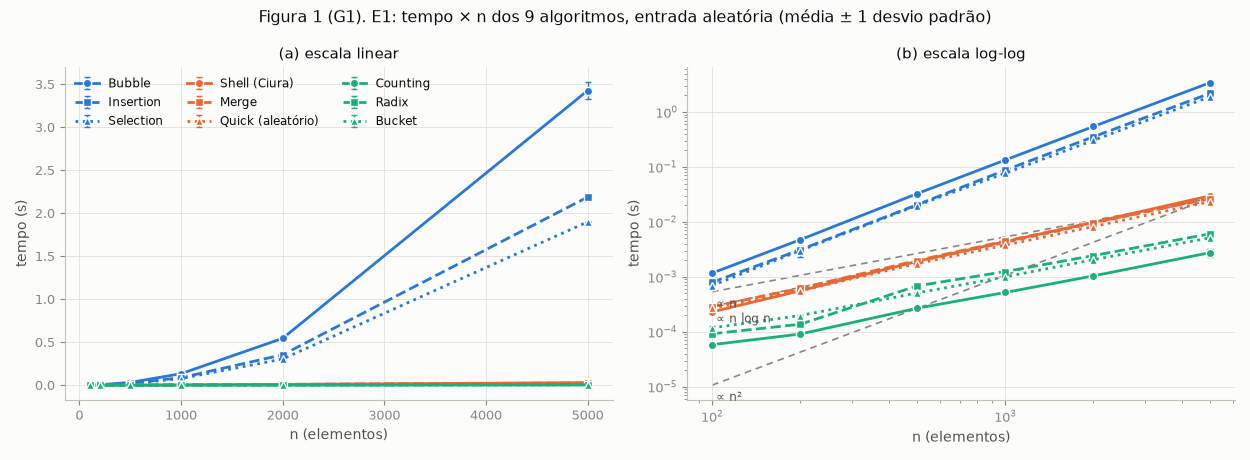

A Figura 1 mostra o tempo dos nove algoritmos em entrada aleatória. Na escala linear (a), os três quadráticos se separam dos demais a partir de $n \approx 1\,000$, e as outras seis curvas ficam praticamente sobre o eixo. Na escala log-log (b), os algoritmos formam três faixas: os quadráticos, com inclinação próxima à da curva $n^2$; Shellsort, Merge e Quick, próximos de $n\log n$; e os lineares, que foram os mais rápidos em todos os tamanhos. Em $n = 5\,000$, o Counting Sort levou 2,8 ms e o Bubble Sort 3,43 s, cerca de 1 240 vezes mais.

**Tabela 1. E1: tempo médio (ms) em $n = 5\,000$, por tipo de entrada.**

| Algoritmo | aleatória | ordenada | inversa | quase ordenada |
|---|---:|---:|---:|---:|
| Bubble | 3 426,0 | 0,9 | 4 396,0 | 2 161,9 |
| Insertion | 2 187,4 | 1,2 | 4 302,1 | 56,3 |
| Selection | 1 899,6 | 1 895,0 | 1 931,1 | 1 893,7 |
| Shellsort (Ciura) | 29,9 | 10,2 | 19,2 | 19,7 |
| Merge | 26,7 | 21,7 | 22,2 | 24,0 |
| Quick (aleatório) | 23,4 | 18,2 | 20,4 | 20,3 |
| Counting | 2,8 | 2,7 | 2,5 | 2,5 |
| Radix (base 256) | 6,1 | 5,8 | 5,9 | 5,8 |
| Bucket | 5,1 | 5,1 | 5,1 | 5,1 |

Na entrada ordenada, Bubble (0,9 ms) e Insertion (1,2 ms) foram os mais rápidos de todos, à frente até do Counting Sort. O Selection Sort levou cerca de 1,9 s em todos os tipos. Na entrada inversa, Bubble e Insertion foram os mais lentos, com 1,3 e 2,0 vezes o próprio tempo na aleatória. Na quase ordenada, o Insertion Sort (56,3 ms) foi 39 vezes mais rápido que na aleatória, mas ainda 2,3 a 2,8 vezes mais lento que Merge e Quick; o Bubble Sort quase não se beneficiou (2,16 s). Entre os subquadráticos, o Shellsort com Ciura foi o mais rápido nas entradas ordenada, inversa e quase ordenada, e o mais lento na aleatória. Como o Bucket Sort recebe reais uniformes em qualquer tipo (Seção 3.5), seus quatro tempos são equivalentes.

### 4.2 Algoritmos quadráticos (E2)

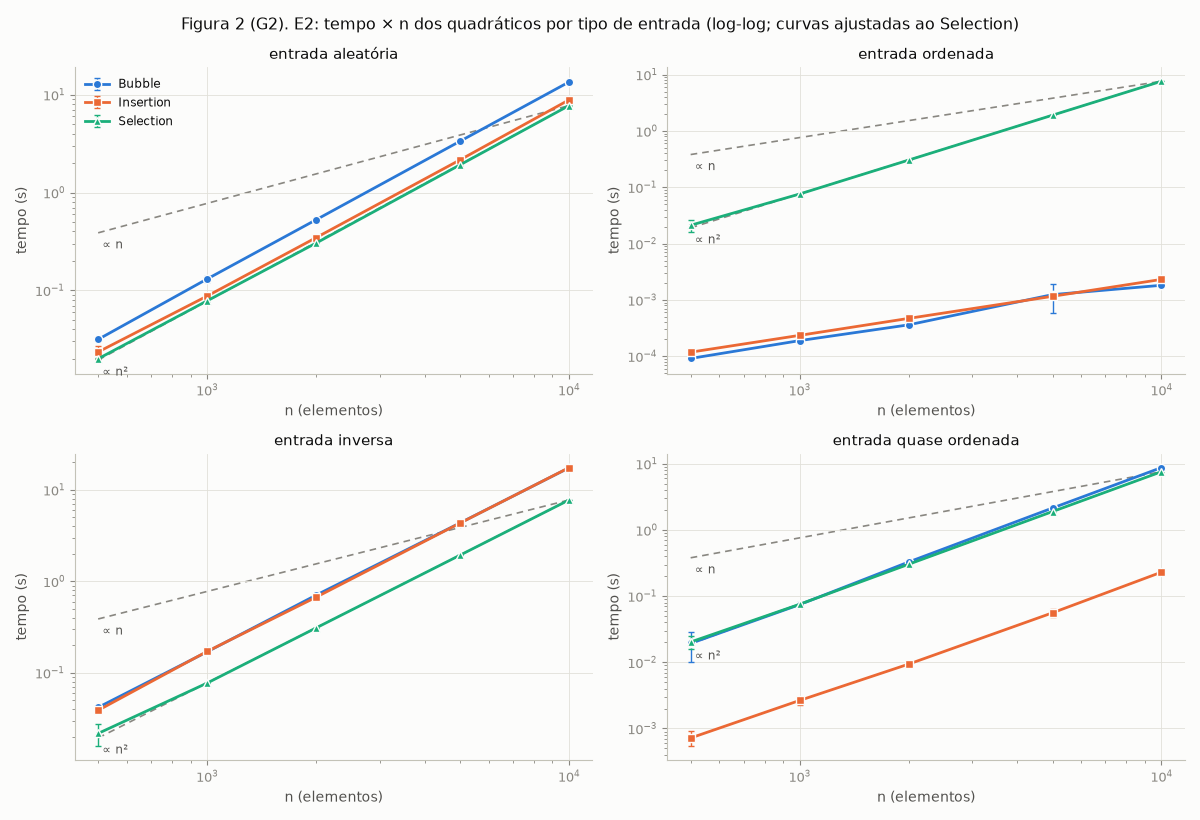

Na Figura 2, a curva do Selection Sort tem a mesma inclinação que $n^2$ nos quatro tipos de entrada, e seus tempos em $n = 10^4$ ficam entre 7,59 s e 7,75 s. Bubble e Insertion seguem $n^2$ nas entradas aleatória e inversa e passam a seguir $n$ na ordenada, em que ordenam $10^4$ elementos em 1,8 ms e 2,3 ms. Na quase ordenada, o Insertion Sort fica 33 a 38 vezes abaixo dos outros dois (0,23 s, contra 8,76 s do Bubble e 7,59 s do Selection em $n = 10^4$), mas sua curva continua paralela à de $n^2$. Na inversa, Bubble e Insertion levam mais que o dobro do tempo do Selection (17,4 s e 17,5 s, contra 7,75 s). Na aleatória, os tempos em $n = 10^4$ foram 13,5 s (Bubble), 8,9 s (Insertion) e 7,8 s (Selection).

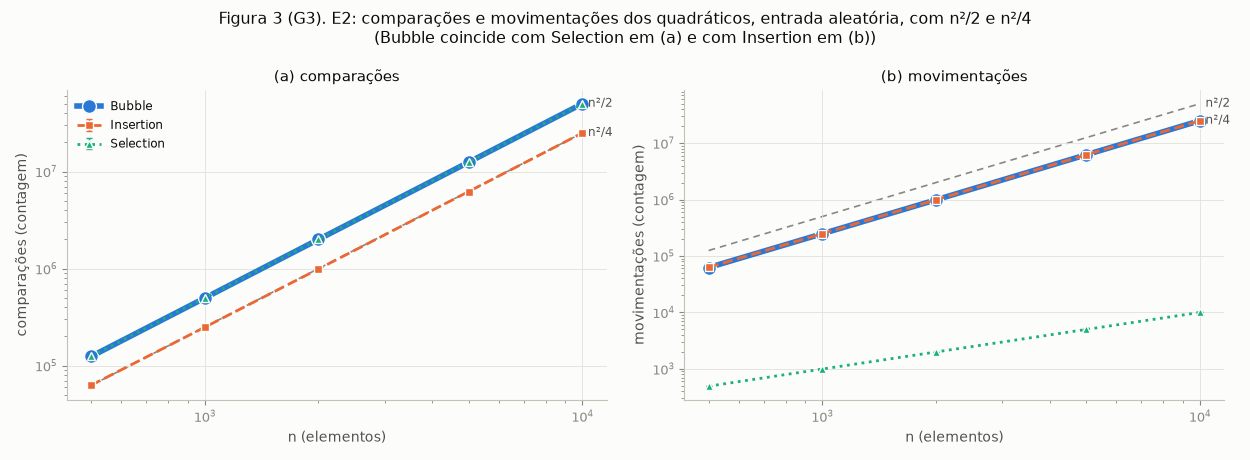

A Figura 3 compara as contagens com $n^2/2$ e $n^2/4$ na entrada aleatória. O Selection Sort faz exatamente $n(n-1)/2$ comparações ($0{,}5000\,n^2$ em $n = 10^4$) e cerca de $n$ trocas. O Bubble Sort faz praticamente o mesmo número de comparações ($0{,}4998\,n^2$), e o Insertion, metade ($0{,}2497\,n^2$). Em movimentações, Bubble e Insertion coincidem em torno de $n^2/4$ ($0{,}2496\,n^2$ e $0{,}2497\,n^2$). Nas entradas que não dependem da *seed*, as contagens são exatas: na ordenada, Bubble e Insertion fazem $n-1$ comparações e nenhuma movimentação; na inversa, os três fazem $n(n-1)/2$ comparações, o Bubble faz $n(n-1)/2$ trocas, o Insertion $n(n-1)/2 + (n-1)$ movimentações e o Selection apenas $n/2$ trocas.

### 4.3 Algoritmos $O(n\log n)$ e Shellsort (E3)

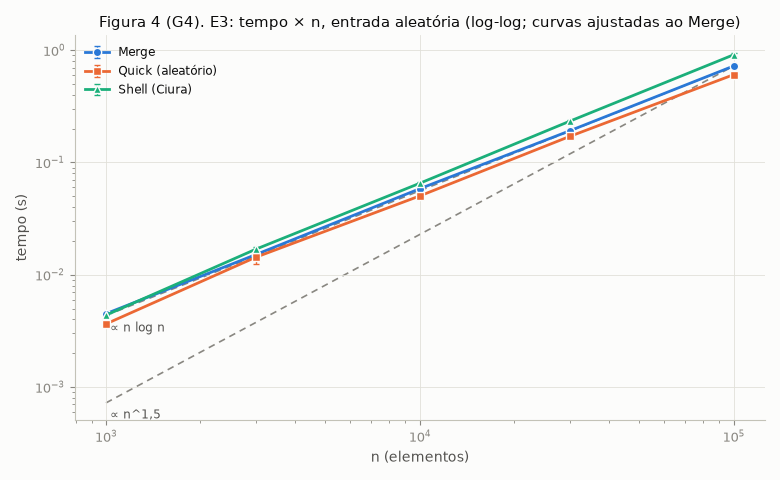

Na Figura 4 (entrada aleatória), as curvas de Merge e Quick aleatório acompanham a inclinação de $n\log n$; a do Shellsort com Ciura é um pouco mais inclinada, mas fica bem abaixo da de $n^{1{,}5}$. Em $n = 10^5$, o Quick aleatório levou 0,60 s, o Merge 0,72 s e o Shellsort 0,91 s.

**Tabela 2. E3: tempo médio (s) em $n = 10^5$, por tipo de entrada.**

| Algoritmo | aleatória | ordenada | inversa | quase ordenada |
|---|---:|---:|---:|---:|
| Shellsort (Shell) | 1,490 | 0,346 | 0,764 | 0,900 |
| Shellsort (Knuth) | 1,427 | 0,221 | 0,505 | 0,739 |
| Shellsort (Ciura) | 0,909 | 0,281 | 0,540 | 0,670 |
| Merge | 0,722 | 0,557 | 0,568 | 0,633 |
| Quick (aleatório) | 0,605 | 0,440 | 0,543 | 0,532 |
| Quick (mediana de 3) | 0,513 | 0,341 | 0,875 | 0,982 |
| Quick (último) | 0,543 | não concluídoᵃ | não concluídoᵇ | 3,591 |

ᵃ Interrompido após $n = 10^4$, em que levou 9,72 s. ᵇ Interrompido em $n = 3\cdot10^4$, em que a única execução levou 77,5 s (8,51 s em $n = 10^4$); ver Seção 3.6.

Nenhum algoritmo foi o mais rápido em todos os tipos: na aleatória, o Quick com mediana de 3 (0,51 s); na ordenada e na inversa, o Shellsort com Knuth (0,22 s e 0,51 s); na quase ordenada, o Quick aleatório (0,53 s). O Merge Sort teve a menor variação entre tipos (0,56 s a 0,72 s). O Quick com mediana de 3, o mais rápido na aleatória, foi o mais lento na inversa entre os algoritmos que chegaram a $n = 10^5$ e o segundo mais lento na quase ordenada, com 3,2 milhões e 5,8 milhões de comparações, contra cerca de 2,0 milhões do Quick aleatório. O Quick com pivô no último elemento foi competitivo na aleatória (0,54 s), mas levou 3,59 s na quase ordenada, com 19,7 milhões de comparações.

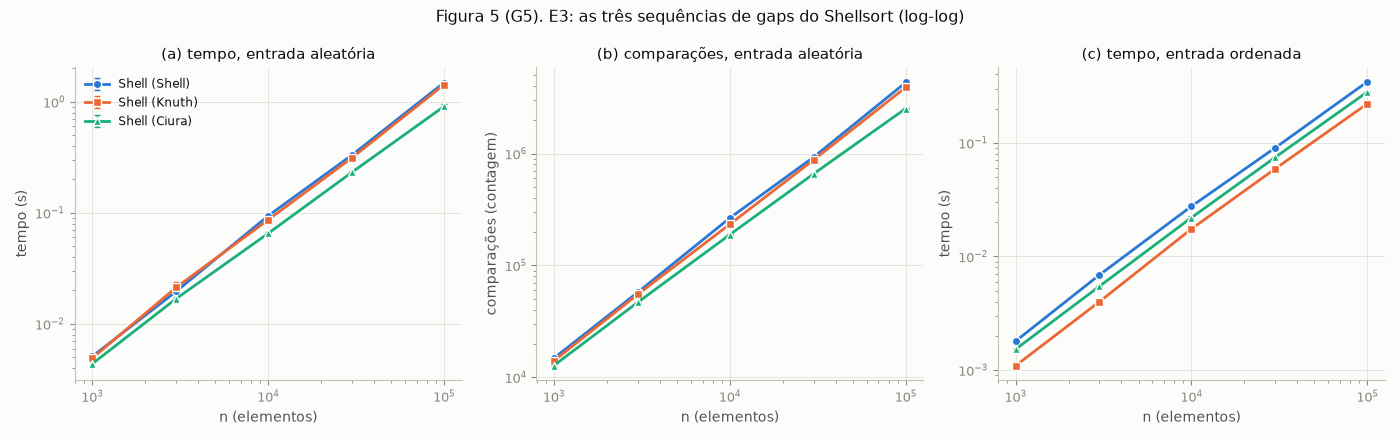

A Figura 5 compara as sequências de *gaps*. Na entrada aleatória, a de Ciura foi a melhor em tempo e em comparações: em $n = 10^5$, fez 2,53 milhões de comparações e levou 0,91 s, contra 3,91 milhões e 1,43 s da de Knuth e 4,32 milhões e 1,49 s da de Shell. Na entrada ordenada (c), a ordem muda e Knuth fica à frente (0,22 s, contra 0,28 s de Ciura e 0,35 s de Shell). Nessa entrada, o número de comparações coincide exatamente com $\sum_h (n - h)$ sobre os *gaps* usados: em $n = 10^5$, 955 719 para Knuth (10 *gaps*), 1 219 454 para Ciura (13 *gaps*) e 1 500 006 para Shell (16 *gaps*).

### 4.4 Algoritmos lineares (E4)

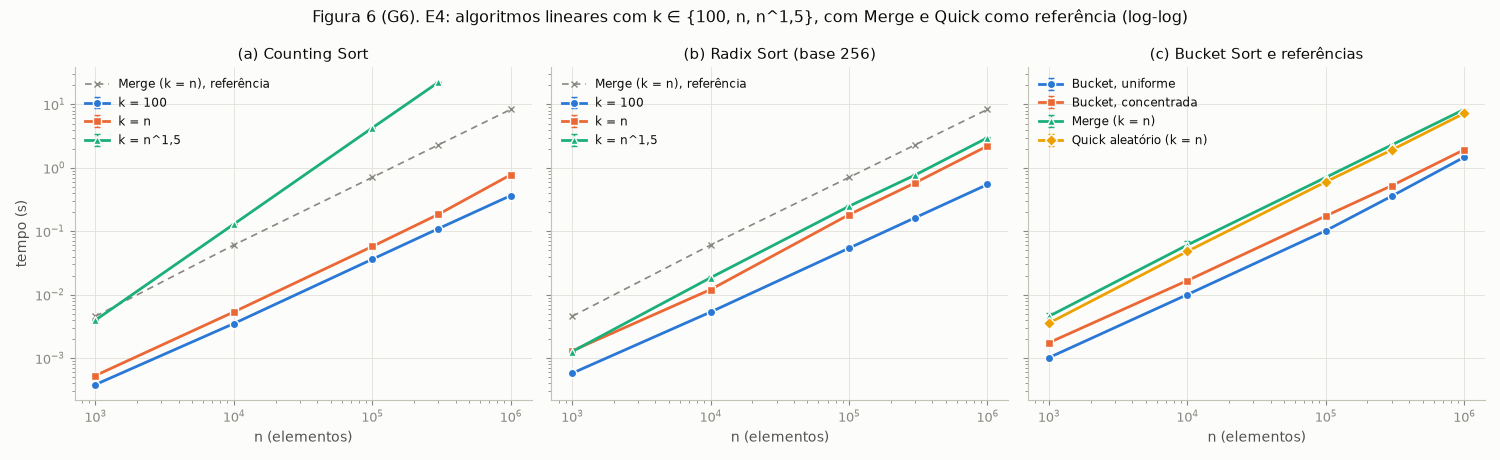

**(a) Counting Sort.** Com $k = 100$ e $k = n$, o tempo cresce linearmente, e $10^6$ elementos são ordenados em 0,37 s e 0,78 s. Com $k = n^{1{,}5}$, a inclinação fica próxima de 1,5: 4,3 s em $n = 10^5$ ($k \approx 3{,}2\cdot10^7$) e 22,3 s em $n = 3\cdot10^5$ ($k \approx 1{,}6\cdot10^8$), tamanho em que a combinação foi interrompida pelo limite de tempo. Nesses dois tamanhos, o Counting foi 6 e 10 vezes mais lento que o Merge Sort.

**(b) Radix Sort (base 256).** O tempo depende muito menos de $k$: em $n = 10^6$, foram 0,55 s com $k = 100$, 2,21 s com $k = n$ e 2,99 s com $k = n^{1{,}5}$. As movimentações registradas ($n$ por passada) mostram o número de passadas: 1 com $k = 100$; 2 com $k = n$ até $n = 10^4$ e 3 a partir de $10^5$; e 2, 3, 4, 4 e 4 com $k = n^{1{,}5}$.

**(c) Bucket Sort.** Foram 1,47 s para $10^6$ reais uniformes e 1,93 s para concentrados. A distribuição concentrada fez 6 vezes mais comparações (2,70 milhões, contra 0,45 milhão) e quase o dobro de movimentações; a razão entre os tempos caiu de 1,7 em $n = 10^3$ para 1,3 em $10^6$.

Em $n = 10^6$, as referências comparativas levaram 8,3 s (Merge) e 7,2 s (Quick aleatório), de 2,4 a 23 vezes o tempo dos lineares, com exceção do Counting com $k = n^{1{,}5}$.

### 4.5 Estratégias de pivô do Quicksort (E5)

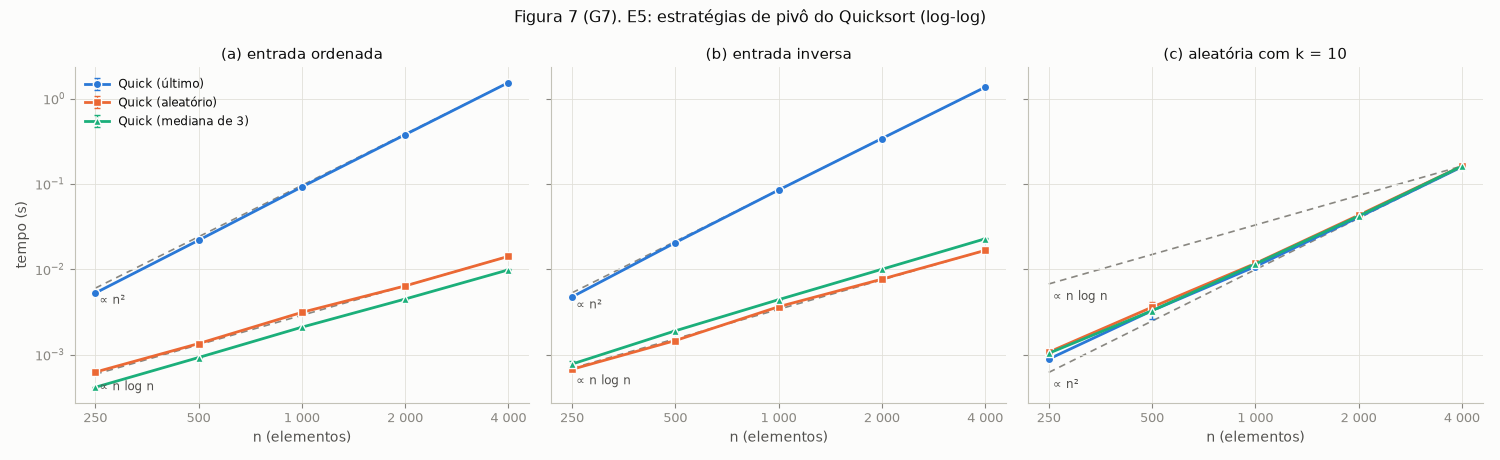

Nas entradas ordenada e inversa (Figuras 7a e 7b), o Quick com pivô no último elemento segue a curva $n^2$ e faz exatamente $n(n-1)/2$ comparações (7 998 000 em $n = 4\,000$), com 1,54 s e 1,36 s nesse tamanho. Os pivôs aleatório e mediana de 3 seguem $n\log n$ e ficam entre 9,9 ms e 22,8 ms; a mediana de 3 é a mais rápida na ordenada (9,9 ms, contra 14,2 ms do aleatório) e a mais lenta na inversa (22,8 ms, contra 16,7 ms). Com $k = 10$ (Figura 7c), as três estratégias têm praticamente o mesmo tempo (159 a 162 ms em $n = 4\,000$) e o mesmo número de comparações (de 814 mil a 826 mil), e as três curvas seguem $n^2$, não $n\log n$.

### 4.6 Algoritmos quadráticos × $O(n\log n)$ em $n$ pequeno (E1)

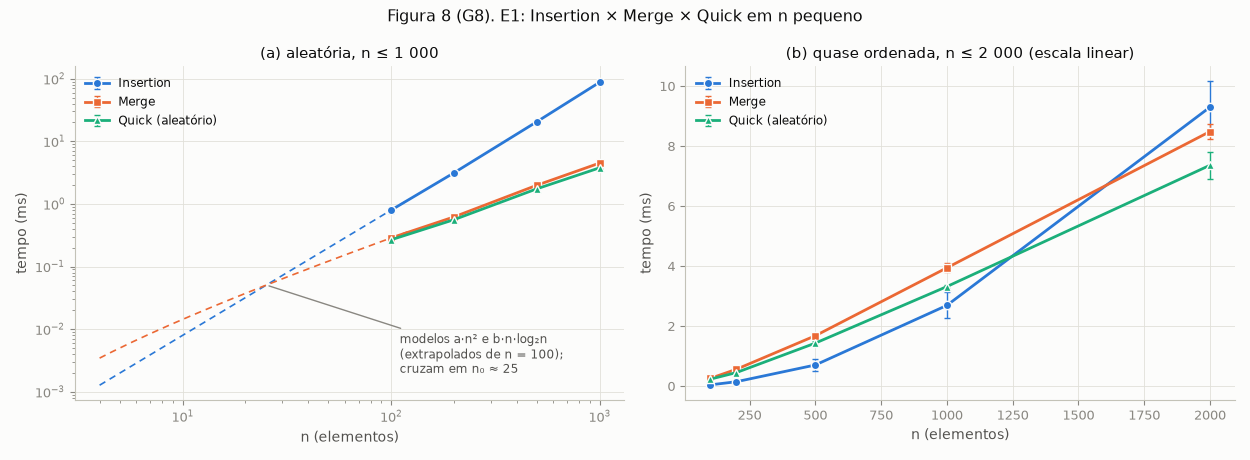

Na entrada aleatória (Figura 8a), o Insertion Sort já é o mais lento dos três no menor tamanho medido: em $n = 100$, levou 0,79 ms, contra 0,29 ms do Merge e 0,27 ms do Quick aleatório. Não há, portanto, cruzamento dentro da faixa do E1. As curvas tracejadas estendem para $n < 100$ os modelos $a\,n^2$ e $b\,n\log_2 n$ ajustados em $n = 100$, que se cruzam por volta de $n_0 \approx 25$ (Seção 5.1). Na entrada quase ordenada (Figura 8b), o Insertion Sort foi o mais rápido até $n = 1\,000$ (2,7 ms, contra 3,3 ms do Quick e 3,9 ms do Merge) e o mais lento em $n = 2\,000$ (9,3 ms, contra 7,4 ms e 8,5 ms); pela interpolação linear, o cruzamento fica em $n \approx 1\,250$ com o Quick e $n \approx 1\,600$ com o Merge. Ainda em $n = 100$ na entrada aleatória, o comparativo mais rápido foi o Shellsort com Ciura (0,23 ms).

### 4.7 Efeito da base no Radix Sort (E6)

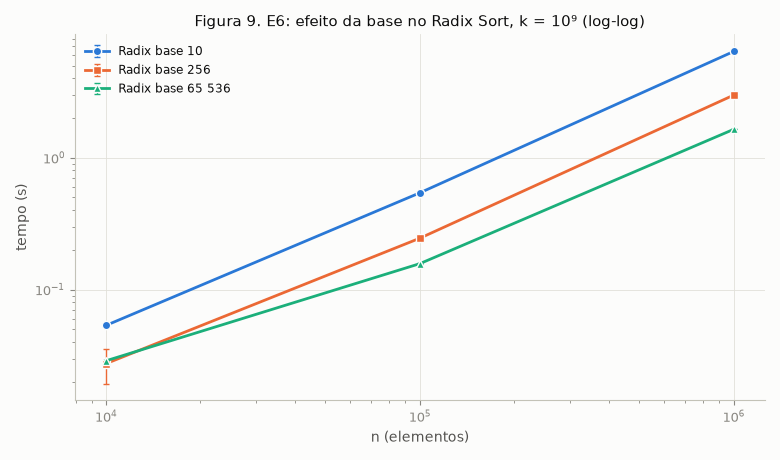

Com $k = 10^9$, o número de passadas foi 9 na base 10, 4 na base 256 e 2 na base 65 536. Em $n = 10^6$, os tempos foram 6,39 s, 2,98 s e 1,64 s, na mesma ordem do número de passadas. Em $n = 10^4$, a base 256 foi a mais rápida (27,4 ms, contra 28,8 ms da base 65 536 e 53,5 ms da base 10).

### 4.8 Expoentes estimados (T1)

As Tabelas 3 e 4 trazem o expoente $\alpha$ de $T(n) \approx c\,n^\alpha$ estimado pelo ajuste log-log da Seção 3.7, com $n \ge 1\,000$, calculado separadamente para cada experimento, como na célula T1 do notebook. A célula de exemplo do enunciado agrupa por (algoritmo, tipo, $k$) e reúne os experimentos; como no E4 o valor de $k$ muda com $n$ nas configurações $k = n$ e $k = n^{1{,}5}$, ela não estima essas combinações.

**Tabela 3 (T1). $\alpha$ do tempo por tipo de entrada (E2 e E3).**

| Algoritmo (experimento) | aleatória | ordenada | inversa | quase ordenada | esperado |
|---|---:|---:|---:|---:|---|
| Bubble (E2) | 2,02 | 1,03 | 2,01 | 2,07 | 2; 1 na ordenada |
| Insertion (E2) | 2,01 | 0,99 | 2,01 | 1,94 | 2; 1 na ordenada |
| Selection (E2) | 2,00 | 2,00 | 2,00 | 2,00 | 2 |
| Shellsort, Shell (E3) | 1,23 | 1,14 | 1,14 | 1,25 | $\le 2$ |
| Shellsort, Knuth (E3) | 1,22 | 1,16 | 1,08 | 1,26 | $\le 1{,}5$ |
| Shellsort, Ciura (E3) | 1,16 | 1,13 | 1,12 | 1,21 | sem limite conhecido |
| Merge (E3) | 1,10 | 1,10 | 1,09 | 1,11 | $n\log n$: pouco acima de 1 |
| Quick, aleatório (E3) | 1,10 | 1,08 | 1,09 | 1,11 | $n\log n$ |
| Quick, mediana de 3 (E3) | 1,11 | 1,10 | 1,15 | 1,16 | $n\log n$ |
| Quick, último (E3) | 1,12 | 2,03ᵃ | 1,99ᵇ | 1,01 | $n\log n$; 2 na ordenada e na inversa |

ᵃ Três pontos ($n = 10^3$ a $10^4$). ᵇ Quatro pontos ($n = 10^3$ a $3\cdot10^4$), o último com uma única *seed*.

**Tabela 4 (T1). $\alpha$ do tempo nos experimentos E4 a E6.**

| Exp. | Algoritmo | Configuração | $\alpha$ | esperado |
|---|---|---|---:|---|
| E4 | Counting | $k = 100$ | 1,00 | 1 |
| E4 | Counting | $k = n$ | 1,05 | 1 |
| E4 | Counting | $k = n^{1{,}5}$ | 1,51 | 1,5 (o termo $k$ domina) |
| E4 | Radix | $k = 100$ | 0,99 | 1 |
| E4 | Radix | $k = n$ | 1,09 | 1 por passada; $d$ cresce com $\log_b n$ |
| E4 | Radix | $k = n^{1{,}5}$ | 1,12 | idem |
| E4 | Bucket | uniforme | 1,05 | 1 |
| E4 | Bucket | concentrada | 1,01 | 1 |
| E4 | Merge (referência) | $k = n$ | 1,09 | $n\log n$ |
| E4 | Quick aleatório (referência) | $k = n$ | 1,10 | $n\log n$ |
| E5 | Quick, último | ordenada / inversa | 2,03 / 2,00 | 2 |
| E5 | Quick, aleatório | ordenada / inversa | 1,09 / 1,10 | $n\log n$ |
| E5 | Quick, mediana de 3 | ordenada / inversa | 1,12 / 1,18 | $n\log n$ |
| E5 | Quick: último / aleatório / mediana de 3 | aleatória, $k = 10$ | 1,94 / 1,89 / 1,90 | ver Seção 5.2 |
| E6 | Radix: base 10 / 256 / 65 536 | $k = 10^9$ | 1,04 / 1,02 / 0,88 | 1 |

Os quadráticos ficaram entre 2,00 e 2,07, exceto Bubble e Insertion na entrada ordenada (1,03 e 0,99). Merge e Quick (aleatório e mediana de 3) ficaram entre 1,08 e 1,18. O Shellsort ficou entre 1,08 e 1,26, sempre abaixo de 1,5. Os lineares ficaram entre 0,99 e 1,05 com $k$ fixo ou proporcional a $n$; o Counting com $k = n^{1{,}5}$ chegou a 1,51, e o Radix com $k = n$ e $k = n^{1{,}5}$ a 1,09 e 1,12. O único valor claramente abaixo de 1 foi o do Radix com base 65 536 no E6 (0,88). No E1, que não aparece nas tabelas, o Radix teve $\alpha$ entre 0,98 e 0,99, o Bucket entre 1,00 e 1,01 e o Counting entre 1,01 e 1,09.

### 4.9 Razões $T(n)/g(n)$ (T2)

**Tabela 5 (T2). razões $T(n)/g(n)$; tempos em segundos.**

*(a) E3, entrada aleatória.*

| Algoritmo e razão | $n = 10^3$ | $3\cdot10^3$ | $10^4$ | $3\cdot10^4$ | $10^5$ |
|---|---:|---:|---:|---:|---:|
| Merge: tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 4,51 | 4,36 | 4,39 | 4,28 | 4,35 |
| Merge: comparações $/\,(n\log_2 n)$ | 0,875 | 0,893 | 0,906 | 0,916 | 0,925 |
| Quick aleatório: tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 3,66 | 4,13 | 3,79 | 3,82 | 3,64 |
| Quick aleatório: comparações $/\,(n\log_2 n)$ | 1,077 | 1,172 | 1,157 | 1,240 | 1,243 |
| Shellsort (Ciura): tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 4,38 | 4,87 | 4,91 | 5,21 | 5,48 |
| Shellsort (Ciura): tempo $/\,n^{1{,}5}$ [$10^{-8}$] | 13,8 | 10,3 | 6,53 | 4,47 | 2,88 |

*(b) E2, entrada aleatória.*

| Algoritmo e razão | $n = 500$ | $10^3$ | $2\cdot10^3$ | $5\cdot10^3$ | $10^4$ |
|---|---:|---:|---:|---:|---:|
| Insertion: tempo $/\,n^2$ [$10^{-8}$] | 9,38 | 8,74 | 8,64 | 8,64 | 8,86 |
| Bubble: tempo $/\,n^2$ [$10^{-7}$] | 1,26 | 1,31 | 1,32 | 1,34 | 1,35 |
| Selection: comparações $/\,n^2$ | 0,4990 | 0,4995 | 0,4998 | 0,4999 | 0,5000 |

*(c) E4, entrada aleatória com $k = n$ (Counting) e uniforme (Bucket).*

| Algoritmo e razão | $n = 10^3$ | $10^4$ | $10^5$ | $3\cdot10^5$ | $10^6$ |
|---|---:|---:|---:|---:|---:|
| Counting: tempo $/\,n$ [$10^{-7}$] | 5,31 | 5,35 | 5,76 | 6,16 | 7,78 |
| Bucket: tempo $/\,n$ [$10^{-7}$] | 10,2 | 10,1 | 10,2 | 12,0 | 14,7 |

As razões do Insertion Sort ($n^2$, a partir de $n = 10^3$) e do Merge Sort ($n\log n$) ficaram estáveis, com variação de cerca de 3% ou menos. A do Quick aleatório oscila entre 3,64 e 4,13, sem tendência. As razões de comparações do Merge e do Quick crescem lentamente com $n$, de 0,875 a 0,925 e de 1,08 a 1,24. No Shellsort, a razão com $n\log n$ cresce 25% na faixa e a razão com $n^{1{,}5}$ cai quase cinco vezes. A razão do Bubble cresce 7% de $n = 500$ a $10^4$, e as do Counting e do Bucket crescem 35% e 44% entre $n = 10^5$ e $10^6$.

### 4.10 Variabilidade das medições

O coeficiente de variação (desvio padrão dividido pela média) dos tempos entre *seeds* teve mediana entre 0,5% (E4 com $k = 100$) e 2,8% (E1), conforme o experimento. Nas entradas aleatórias, o coeficiente de variação das comparações teve mediana entre 0,09% (E2) e 2,4% (E3). Nas entradas ordenada e inversa, que não dependem da *seed*, as contagens foram idênticas nas cinco execuções em todos os algoritmos, inclusive no Quick aleatório (desvio padrão zero), de modo que toda a variação de tempo nessas entradas é ruído de medição. A maior distância entre uma execução e a mediana da sua combinação foi de 2,8 vezes, num tempo de décimos de milissegundo (Bubble em entrada quase ordenada, $n = 100$); nos tamanhos grandes, as execuções de uma mesma combinação ficaram, em geral, a poucos por cento umas das outras.

As contagens desta execução foram idênticas às da execução anterior, descartada (Seção 3.6), em todas as combinações; os tempos medianos ficaram entre 3,1% menores e 0,5% maiores, conforme o experimento.

## 5. Análise crítica

### 5.1 Quadráticos × $O(n\log n)$ para $n$ pequeno

Em entrada aleatória, nenhum quadrático superou Merge ou Quick em nenhum tamanho medido: o cruzamento ocorre abaixo de $n = 100$, o menor tamanho do E1 (Figura 8a). Na entrada ordenada, Bubble e Insertion foram mais rápidos que todos os comparativos em todos os tamanhos (Tabela 1), e na quase ordenada o Insertion Sort venceu Merge e Quick até $n = 1\,000$, com cruzamento entre 1 250 e 1 600 (Figura 8b).

Os modelos $T_{ins}(n) \approx a\,n^2$ e $T_{merge}(n) \approx b\,n\log_2 n$, ajustados com os tempos de $n = 100$ na entrada aleatória, dão $a = 0{,}794\text{ ms}/100^2 \approx 7{,}9\cdot10^{-8}$ s e $b = 0{,}286\text{ ms}/(100\log_2 100) \approx 4{,}3\cdot10^{-7}$ s. Igualando os modelos, $n_0 = (b/a)\log_2 n_0 \approx 5{,}4\log_2 n_0$, cuja solução é $n_0 \approx 25$; com o Quick aleatório no lugar do Merge, $n_0 \approx 23$, e ajustando em $n = 200$ ou $500$ os valores ficam entre 20 e 25. A previsão é coerente com a observação de que o cruzamento ocorre abaixo de 100, mas o E1 não tem tamanhos menores para confirmá-la diretamente.

A origem das constantes fica clara quando o tempo é dividido pelo número de operações contadas (comparações mais movimentações). Na entrada aleatória, o custo por operação foi parecido em todos os comparativos: cerca de 155 ns no Selection, 180 ns no Insertion e no Bubble, 200 ns no Quick e 225 ns no Merge. Em Python instrumentado, cada operação é uma chamada de função, e esse custo domina. A constante oculta de cada algoritmo vem, portanto, principalmente do número de operações que ele faz: em $n = 100$, o Insertion faz cerca de $n^2/2 \approx 5\,000$ operações, e o Merge cerca de $1{,}9\,n\log_2 n \approx 1\,300$, além do custo das chamadas recursivas e das cópias para o vetor auxiliar. O mesmo raciocínio explica por que o Bubble Sort foi o mais lento na aleatória: ele faz $n^2/2$ comparações e $n^2/4$ trocas (cerca de $0{,}75\,n^2$ operações), contra $0{,}5\,n^2$ do Insertion, e a razão entre os tempos em $n = 10^4$ (1,52) é próxima de $0{,}75/0{,}5$.

Esse é o motivo pelo qual implementações reais, como o Timsort e o *introsort*, ordenam subvetores pequenos com Insertion Sort: abaixo de algumas dezenas de elementos, a menor quantidade de operações por elemento e a ausência de recursão compensam o crescimento quadrático. O Merge Sort híbrido com limiar $L$ (item opcional do enunciado) não foi implementado.

### 5.2 Impacto da escolha do pivô no Quicksort

Com pivô no último elemento, as entradas ordenada e inversa levaram ao pior caso: $\alpha = 2{,}03$ e $1{,}99$ no E3 e $2{,}03$ e $2{,}00$ no E5, com exatamente $n(n-1)/2$ comparações em todos os tamanhos, inclusive nas 449 985 000 comparações da única execução em $n = 3\cdot10^4$ na inversa. É o comportamento da recorrência $T(n) = T(n-1) + \Theta(n)$: na ordenada, o pivô é sempre o máximo e uma das partes fica vazia; na inversa, o pivô é o mínimo, e a troca final leva o máximo para o fim do subvetor, de modo que as partições alternam entre mínimo e máximo, sempre com uma parte vazia. A entrada quase ordenada também prejudicou essa estratégia (3,59 s e 19,7 milhões de comparações em $n = 10^5$, contra 0,53 s e 2,0 milhões do pivô aleatório), embora com $\alpha \approx 1{,}01$: as comparações ficaram entre 150 e 200 por elemento em todos os tamanhos. Uma explicação plausível, não verificada, é que o pivô do fim é quase sempre um dos maiores valores do trecho, e o custo fica limitado pela distância média entre os elementos fora de lugar (da ordem de 50 posições, já que cerca de 2% deles foram trocados), que não depende de $n$.

Com o pivô aleatório, o pior caso continua possível, mas exige que o sorteio escolha um extremo do subvetor em praticamente todas as partições, e a probabilidade disso cai muito depressa com $n$. Os dois conceitos diferem na fonte da aleatoriedade. No caso médio sobre as entradas, o algoritmo é determinístico e a média é tomada sobre uma distribuição suposta para as entradas (por exemplo, todas as permutações igualmente prováveis); uma entrada ruim continua ruim. No tempo esperado sobre as escolhas do algoritmo, a garantia vale para qualquer entrada fixa, e a média é sobre os sorteios internos. Os dados confirmam a análise do caso esperado: as comparações do Quick aleatório ficaram a até 2,3% do valor teórico $2(n+1)H_n - 4n$ (10 736 contra 10 986 em $n = 10^3$; 153 695 contra 155 772 em $10^4$; 2 063 943 contra 2 018 053 em $10^5$). Como a semente do pivô é fixa (0), cada entrada sempre recebe a mesma sequência de pivôs; quem conhecesse a semente poderia construir uma entrada de pior caso.

Com $k = 10$, as três estratégias degradaram igualmente ($\alpha$ entre 1,89 e 1,94 no tempo e entre 1,93 e 1,96 nas comparações). A causa é a partição de Lomuto com $\le$: os elementos iguais ao pivô vão todos para a esquerda, de modo que um subvetor formado só por cópias de um mesmo valor é particionado com uma parte vazia a cada passo. Com $k$ valores distintos, cada valor tem cerca de $n/k$ cópias, e o custo total fica em torno de $k\cdot(n/k)^2/2 = n^2/(2k)$. Para $k = 10$ e $n = 4\,000$, isso dá 800 000 comparações; foram medidas de 814 mil a 826 mil. Nenhuma estratégia de pivô ajuda, porque dentro desses blocos todos os candidatos têm o mesmo valor; a solução seria a partição de três vias de Dijkstra (SEDGEWICK; WAYNE, 2011), que não foi implementada.

Não houve diferença sistemática de desvio padrão entre as estratégias. Nas entradas ordenada e inversa, que são iguais para todas as *seeds*, as contagens tiveram desvio zero nas três estratégias, inclusive na aleatória (por causa da semente fixa), e os coeficientes de variação do tempo, de 0,1% a 8%, são apenas ruído de medição. Com $k = 10$, a variação vem das diferentes entradas e é parecida nas três.

### 5.3 Efeito da sequência de *gaps* no Shellsort

Na entrada aleatória, a sequência de Ciura foi a melhor em tempo e em comparações (0,91 s e 2,53 milhões em $n = 10^5$), seguida de Knuth (1,43 s e 3,91 milhões) e de Shell (1,49 s e 4,32 milhões), com $\alpha$ de 1,16, 1,22 e 1,23. É o resultado esperado: Ciura obteve seus incrementos por busca experimental, escolhendo os que minimizam o número médio de comparações em permutações aleatórias (CIURA, 2001), e é por esse desempenho médio que ela é a versão principal deste trabalho. Uma interpretação usual é a razão entre *gaps* consecutivos, de cerca de 2,25 em Ciura, contra 3 em Knuth e 2 em Shell: com razão 2, *gaps* consecutivos compartilham o fator 2, e parte de cada passada repete comparações da anterior; com razão 3, cada passada recebe um vetor menos preparado pela anterior. Essa explicação é qualitativa e não foi testada aqui.

Nas entradas ordenada e inversa, Knuth foi a mais rápida. Na ordenada, isso se explica pelo número de *gaps*: cada passada custa exatamente $n - h$ comparações, e a sequência de Knuth, limitada a $h < n/3$, usa 10 *gaps*, contra 13 de Ciura (estendida até perto de $n$) e 16 de Shell. As contagens medidas coincidem com $\sum_h (n-h)$ (Seção 4.3).

Os resultados são compatíveis com os limites conhecidos. Para Knuth, $\alpha = 1{,}22$ fica abaixo de $3/2$, como esperado de um limite superior $O(n^{3/2})$. Para Shell, $\alpha = 1{,}23$ está longe de 2, o que também é esperado: o pior caso $\Theta(n^2)$ dessa sequência exige $n$ potência de 2 e uma entrada específica (Seção 2.3), e os experimentos usam entradas aleatórias e tamanhos que não são potências de 2. A razão $T(n)/(n\log n)$ do Shellsort com Ciura cresce lentamente e a razão $T(n)/n^{1{,}5}$ diminui (Tabela 5a), o que situa seu crescimento entre $n\log n$ e $n^{1{,}5}$ na faixa medida.

O Shellsort foi competitivo com Merge e Quick. Na entrada aleatória, a versão de Ciura foi 1,3 a 1,5 vez mais lenta que os dois em $n = 10^5$, e a diferença tende a crescer com $n$, já que seu $\alpha$ é maior. Na entrada ordenada, as sequências de Knuth e Ciura foram mais rápidas que Merge e Quick aleatório em todos os tamanhos do E3, e na inversa a partir de $n = 10^4$; na quase ordenada, a de Ciura ficou entre o Merge e o Quick com mediana de 3 (Tabela 2).

### 5.4 Quando os algoritmos lineares são vantajosos

**Counting Sort e o valor de $k$.** Com $k = 100$ e $k = n$, o Counting Sort foi linear ($\alpha$ = 1,00 e 1,05) e o mais rápido de todos os algoritmos. Com $k = n^{1{,}5}$, o termo $k$ de $\Theta(n + k)$ domina desde o primeiro tamanho: em $n = 10^3$, $k \approx 32\,n$ e o tempo já é 7,5 vezes o do caso $k = n$; o $\alpha$ medido (1,51) é o do próprio $k$. Em $n = 3\cdot10^5$, o vetor de contagem tem $1{,}6\cdot10^8$ posições. Em CPython, uma lista ocupa 8 bytes por posição (cerca de 1,3 GB), e depois das somas prefixas cada posição aponta para um inteiro próprio, de modo que a memória necessária chega a alguns gigabytes. Essa é uma estimativa: a memória não foi medida e não houve erro de memória. Em $n = 10^6$ ($k = 10^9$), seriam necessárias dezenas de gigabytes, mais do que os 16 GB da máquina; o limite de tempo interrompeu a combinação antes dessa tentativa.

**Radix Sort.** O Radix foi muito menos afetado por $k$ porque seu custo cresce com o número de passadas, $d = \lfloor\log_b(M-m)\rfloor + 1$, e não com $k$. Em $n = 10^6$, os tempos de 0,55 s, 2,21 s e 2,99 s correspondem a 1, 3 e 4 passadas, ou seja, de 0,55 a 0,75 µs por elemento e por passada. Com $k = n$, $d$ cresce com $\log_{256} n$, e isso explica por que $T(n)/n$ do Radix aumenta com $n$ (Figura 6b). No E6, a base 65 536 foi a melhor nos tamanhos grandes (2 passadas), e a base 10 a pior (9 passadas). Em $n = 10^4$, a base 256 venceu a de 65 536 porque o vetor de contagem desta tem 65 536 posições por passada, mais do que os $10^4$ elementos: o termo $b$ de $\Theta(d(n+b))$ passa a pesar, e é também por isso que o $\alpha$ da base 65 536 ficou em 0,88. Isso é coerente com o resultado clássico de que a melhor base fica próxima de $n$.

**Bucket Sort.** Com distribuição uniforme, o Bucket Sort foi linear ($\alpha = 1{,}05$), como prevê a análise $\Theta(n)$ do caso médio. Com a distribuição concentrada, o $\alpha$ foi 1,01, e o algoritmo continuou linear, apenas com uma constante maior (1,3 a 1,7 vez o tempo, 6 vezes as comparações). A teoria também prevê esse resultado, porque a distribuição concentrada usada coloca 90% dos valores em 10% dos baldes, com cerca de 9 elementos por balde em média, número que não cresce com $n$. O pior caso $\Theta(n^2)$ exige que uma fração crescente dos elementos caia no mesmo balde, situação que os experimentos não testaram.

**Lineares × Merge e Quick em Python.** Para $n$ grande, os lineares foram de fato mais rápidos: em $n = 10^6$, o Counting ($k = n$) levou 0,78 s, o Bucket uniforme 1,47 s e o Radix 2,21 s, contra 7,2 s do Quick aleatório e 8,3 s do Merge. A exceção foi o Counting com $k$ muito maior que $n$, até 10 vezes mais lento que o Merge. Três fatores pesam nessa comparação. A instrumentação penaliza mais os comparativos, que fazem uma chamada de função por comparação e por movimentação, enquanto boa parte do trabalho dos lineares (contagem, somas prefixas, cálculo dos dígitos) não é instrumentada. A alocação de memória pesa nos lineares quando $k$ ou $n$ crescem: o tempo por elemento do Counting e do Bucket aumentou 35% e 44% entre $10^5$ e $10^6$, possivelmente por efeitos de cache e de memória. E "linear" pressupõe hipóteses sobre a entrada (inteiros num intervalo limitado, dígitos, distribuição uniforme) que, quando violadas, anulam a vantagem, como no caso $k = n^{1{,}5}$.

**Comparações entre comparativos e não comparativos.** Counting e Radix fazem zero comparações, mas leem e escrevem cada elemento várias vezes e percorrem o vetor de contagem, e nada disso entra em `comp`. Por isso, o número de comparações não serve para comparar os dois grupos. Métricas mais justas são o tempo, as movimentações, que os dois grupos têm, ou uma contagem de todas as operações elementares, incluindo os acessos por índice.

### 5.5 Teoria × prática

**Expoentes.** Os expoentes ficaram próximos dos esperados na maioria dos casos (Tabelas 3 e 4): 2,00 a 2,07 nos quadráticos, 0,99 a 1,03 em Bubble e Insertion na entrada ordenada, 1,08 a 1,11 em Merge e Quick aleatório (o esperado para $n\log n$ na faixa de $10^3$ a $10^5$ é cerca de $1 + 1/\ln n \approx 1{,}1$) e cerca de 1 nos lineares sob suas hipóteses. As maiores discrepâncias foram estas:

- Na entrada quase ordenada, Bubble e Insertion tiveram $\alpha \approx 2$. O gerador troca cerca de $n/100$ pares de posições sorteadas, a uma distância média de $n/3$; cada troca cria cerca de $2n/3$ inversões, e o total fica em torno de $n^2/150$. As comparações do Insertion em $n = 10^4$ (652 828, cerca de $n^2/153$) confirmam essa conta. Com essa definição, a entrada quase ordenada continua $\Theta(n^2)$ para Bubble e Insertion, com uma constante cerca de 38 vezes menor no Insertion.
- O Radix com base 65 536 teve $\alpha = 0{,}88$ no E6. Até $n = 10^4$, o vetor de contagem dessa base é maior que o número de elementos, e o custo inicial não é proporcional a $n$ (Seção 5.4).
- O Radix com $k = n$ e $k = n^{1{,}5}$ teve $\alpha$ de 1,09 e 1,12. Nessas configurações o número de passadas cresce com $n$, e o custo passa a ser $\Theta(n \log_b n)$.
- O tempo por elemento do Counting e do Bucket cresceu a partir de $10^5$ (Tabela 5c), e o do Bubble, mais devagar (Tabela 5b). A explicação mais provável são efeitos de memória e de cache (o processador tem 25 MB de cache L3, e uma lista de $10^6$ referências já ocupa 8 MB), mas esse ponto não foi medido.
- As razões de comparações do Merge e do Quick crescem lentamente (Tabela 5a), como esperado: $2(n+1)H_n - 4n \approx 1{,}39\,n\log_2 n - O(n)$, e o termo negativo de ordem $n$ faz a razão subir devagar em direção a 1,39; no Merge, a razão sobe em direção a 1 pelo mesmo motivo.

**Contagens × tempo.** As contagens foram muito mais estáveis que o tempo: são determinísticas para uma dada entrada (desvio zero nas entradas ordenada e inversa e valores idênticos nas duas execuções completas), enquanto o tempo inclui ruído do sistema operacional, do cache e da memória e variou até cerca de 3% entre as duas execuções. Para validar a análise assintótica, as contagens são a melhor métrica: várias delas reproduziram fórmulas fechadas exatamente ($n(n-1)/2$, $\sum_h (n-h)$) ou quase ($n^2/(2k)$, $2(n+1)H_n - 4n$). Para escolher um algoritmo num sistema real, o tempo é mais informativo, porque inclui o que as contagens ignoram: o custo de cada operação, a alocação de memória e o trabalho não contado. Um exemplo: em $n = 10^5$, o Quick aleatório fez 34% mais comparações que o Merge, mas foi 16% mais rápido, porque fez menos movimentações (1,0 milhão contra 1,7 milhão) e não copia para um vetor auxiliar.

**Tabela 6. Recomendações por cenário, com base nos dados.**

| Cenário | Escolha | Justificativa |
|---|---|---|
| $n$ pequeno | Insertion Sort até algumas dezenas de elementos; Shellsort (Ciura) por volta de $n = 100$ | $n_0$ estimado entre 23 e 25; em $n = 100$, o Shellsort foi o comparativo mais rápido (Seção 4.6) |
| Dados quase ordenados | Insertion Sort se as inversões forem poucas e locais; senão, Quick aleatório ou Shellsort | linear na entrada ordenada; com inversões a longa distância, só compensa até $n \approx 10^3$ |
| Estabilidade necessária | Merge Sort; Counting ou Radix para inteiros | estáveis por construção (testes da Seção 3.3) e $\Theta(n\log n)$ ou linear |
| Pouca memória extra | Shellsort ou Quicksort (aleatório) | *in-place*; pilha $O(\log n)$ no Quick; competitivos com o Merge (Tabela 2) |
| Inteiros em intervalo pequeno | Counting Sort ($k \lesssim n$); Radix com base grande para $k$ grande | os mais rápidos do trabalho; Radix pouco sensível a $k$ (Figura 6) |
| Pior caso garantido | Merge Sort | $\Theta(n\log n)$ em qualquer entrada, menor variação entre tipos (de 0,56 a 0,72 s em $10^5$) |

### 5.6 Confronto com as previsões

As previsões da Parte E do notebook de algoritmos se confirmaram em parte. Na entrada aleatória, os mais rápidos foram de fato os lineares, seguidos de Quick e Merge, e o mais lento foi o Bubble; mas o segundo mais lento foi o Insertion (2,19 s em $n = 5\,000$), e não o Selection (1,90 s): os dois fazem cerca de $n^2/2$ operações, mas as do Selection são quase todas comparações, que custaram menos (cerca de 155 ns, contra 180 ns). Na entrada ordenada, Bubble e Insertion foram os mais rápidos e o Selection o mais lento, como previsto. Na entrada quase ordenada, a previsão de comportamento linear para Bubble e Insertion não se confirmou: o Bubble levou praticamente o mesmo tempo que na aleatória, e o Insertion, embora muito mais rápido, perdeu para todos os subquadráticos a partir de algum $n$ entre 1 000 e 2 000, ambos com $\alpha \approx 2$ (Seção 5.5). Na entrada inversa, a previsão de que Merge e Quick seriam os mais rápidos não se confirmou: os lineares e o Shellsort com Ciura foram mais rápidos que os dois. Quanto aos expoentes, os quadráticos e os $n\log n$ ficaram na faixa prevista (2 e de 1,05 a 1,15), enquanto o Shellsort com Ciura ficou no limite inferior dela ou abaixo (de 1,12 a 1,21, contra 1,20 a 1,33 previstos). O efeito de $k$ no Counting Sort e o crescimento do número de passadas do Radix com $n$ não estavam nas previsões.

### 5.7 Limitações

- Os experimentos rodaram numa única máquina, com uma versão do Python e uma execução por *seed*; a média de 5 execuções é sensível a valores isolados.
- O E1 começa em $n = 100$, abaixo do qual estaria o cruzamento na entrada aleatória; o E3 não incluiu os tamanhos opcionais ($3\cdot10^5$ e $10^6$); o Quick com pivô no último elemento tem três pontos na entrada ordenada e quatro na inversa, o último com uma única *seed*, e o Counting com $k = n^{1{,}5}$ tem quatro, também com o último de uma *seed*.
- A entrada quase ordenada tem $\Theta(n^2)$ inversões e não representa o cenário de poucas inversões locais; a distribuição concentrada não é um pior caso do Bucket Sort; nenhum tamanho é potência de 2 e nenhuma entrada foi construída para o pior caso da sequência de Shell.
- Como a semente do pivô aleatório é fixa, a variação devida às escolhas de pivô não foi amostrada; todas as diferenças entre *seeds* vêm das entradas.
- O consumo de memória não foi medido; os valores citados na Seção 5.4 são estimativas.
- O Merge Sort híbrido com Insertion Sort (opcional) e a partição de três vias do Quicksort não foram implementados.

## 6. Conclusões

Os experimentos confirmaram as classes de complexidade previstas pela teoria. Os quadráticos tiveram expoentes entre 2,00 e 2,07, os algoritmos $n\log n$ entre 1,08 e 1,11 nas versões principais, e os lineares cerca de 1 quando suas hipóteses foram respeitadas. As contagens de operações reproduziram fórmulas fechadas: $n(n-1)/2$ comparações no Selection Sort e no pior caso do Quicksort, $\sum_h(n-h)$ no Shellsort em vetor ordenado, cerca de $n^2/(2k)$ no Quicksort com valores repetidos e o valor esperado $2(n+1)H_n - 4n$ do Quicksort aleatório, a menos de 2,3%.

Retomando as perguntas da introdução:

1. Os tempos e as contagens seguiram as classes previstas; os expoentes estimados concordaram com os esperados, e as principais exceções têm causa identificada (definição da entrada quase ordenada e número de passadas e termo $b$ do Radix).
2. Em entrada aleatória, os quadráticos só seriam mais rápidos abaixo de $n_0$ entre 23 e 25, segundo os modelos ajustados; em entrada quase ordenada, o Insertion Sort venceu Merge e Quick até $n$ entre 1 250 e 1 600. As constantes ocultas vêm principalmente do número de operações por elemento, já que o custo de cada operação instrumentada é parecido entre os algoritmos.
3. O pivô no último elemento leva a $\Theta(n^2)$ em entradas ordenadas e inversas; o pivô aleatório e a mediana de 3 evitam esse caso; e nenhuma estratégia resolve os valores repetidos com a partição de Lomuto.
4. A sequência de Ciura foi a melhor em entrada aleatória, e a de Knuth nas entradas ordenada e inversa; a de Shell foi a pior em quase todos os casos.
5. Os lineares compensam quando suas hipóteses valem: foram de 2,4 a 23 vezes mais rápidos que Merge e Quick em $n = 10^6$, mas o Counting Sort com $k = n^{1{,}5}$ ficou até 10 vezes mais lento que o Merge e exigiria memória além da disponível.
6. Contagens e tempo não são equivalentes: as contagens são a métrica certa para validar a análise assintótica, e o tempo, para escolher um algoritmo na prática.

Na prática, para uso geral, o Quicksort com pivô aleatório e o Merge Sort são as escolhas mais seguras entre os comparativos, o segundo quando estabilidade ou pior caso garantido importam. O Insertion Sort só compensa em vetores muito pequenos ou com poucas inversões, e os lineares devem ser usados quando as chaves são inteiros num intervalo conhecido, com o Radix de base grande para intervalos maiores.

Como trabalhos futuros, ficam: o Heapsort, que garante $O(n\log n)$ *in-place*; o Merge Sort híbrido com Insertion Sort e a partição de três vias do Quicksort; a comparação com o Timsort do próprio Python; a medição do consumo de memória; mais repetições por *seed* e o uso da mediana; sementes variáveis no pivô aleatório; tamanhos potência de 2 e entradas de pior caso para o Shellsort; e a repetição dos experimentos sem instrumentação ou em uma linguagem compilada.

## Referências

CIURA, M. Best increments for the average case of Shellsort. In: FREIVALDS, R. (ed.). **Fundamentals of Computation Theory (FCT 2001)**. Berlin: Springer, 2001. p. 106–117. (Lecture Notes in Computer Science, v. 2138).

CORMEN, T. H.; LEISERSON, C. E.; RIVEST, R. L.; STEIN, C. **Algoritmos: teoria e prática**. 3. ed. Rio de Janeiro: Elsevier, 2012.

HOARE, C. A. R. Quicksort. **The Computer Journal**, Oxford, v. 5, n. 1, p. 10–16, 1962.

KNUTH, D. E. **The art of computer programming, volume 3: sorting and searching**. 2. ed. Reading: Addison-Wesley, 1998.

PRATT, V. R. **Shellsort and sorting networks**. New York: Garland, 1979.

SEDGEWICK, R.; WAYNE, K. **Algorithms**. 4. ed. Upper Saddle River: Addison-Wesley, 2011.

SHELL, D. L. A high-speed sorting procedure. **Communications of the ACM**, New York, v. 2, n. 7, p. 30–32, 1959.

ZIVIANI, N. **Projeto de algoritmos: com implementações em Java e C++**. São Paulo: Thomson Learning, 2007.